**Задача:** для каждой куки дать оценку от 0 до 1 — насколько вероятно, что это бот-сборщик данных
**Метрика:** Precision при Recall ≥ 0.70.

**План:**
1. Загрузить данные и подготовить метрику
2. Посмотреть на данные и найти подводные камни
3. Собрать признаки из событий (только внутри окна наблюдения)
4. Проверить качество на валидации по времени и сравнить с baseline
5. Обучить финальную модель и сохранить `submission.csv`

## 1. Импорты, данные, метрика

In [1]:
import numpy as np
import pandas as pd
import lightgbm as lgb

SEED = 42  

events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'])
train = pd.read_csv('data/train.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
test = pd.read_csv('data/test.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])

print('train:', train.shape, '| test:', test.shape, '| events:', events.shape)
print('доля ботов в train:', round(train.target.mean(), 4))

FileNotFoundError: [Errno 2] No such file or directory: 'data/events.csv.gz'

Метрика ниже — копия логики из выданного `metric.py` (вставлена прямо в ноутбук,
чтобы он запускался без лишних файлов). Главная особенность: куки с **одинаковым score
нельзя разделять** — порог отмечает всю группу целиком.

In [ ]:
def precision_at_recall(y_true, score, min_recall=0.70):
    """Максимальный precision среди порогов, где recall >= min_recall."""
    y_true = np.asarray(y_true, dtype=int)
    score = np.asarray(score, dtype=float)
    order = np.argsort(-score, kind='mergesort')
    y, s = y_true[order], score[order]
    tp = np.cumsum(y)
    k = np.arange(1, len(y) + 1)
    ends = np.r_[s[1:] != s[:-1], True]      # конец каждой группы одинаковых score
    precision, recall = tp[ends] / k[ends], tp[ends] / y_true.sum()
    ok = recall >= min_recall
    return float(precision[ok].max()) if ok.any() else 0.0


# самопроверка на примере из условия: ответ должен быть 0.8
assert precision_at_recall([1, 0, 1, 1, 1], [5, 4, 3, 2, 1]) == 0.8

## 2. Осмотр данных

Три вещи, которые влияют на всё дальнейшее.

**(а) Test лежит позже train по времени** → валидировать нужно тоже по времени, а не случайным сплитом.

In [ ]:
print('train:', train.window_start_ts.min().date(), '—', train.window_start_ts.max().date())
print('test: ', test.window_start_ts.min().date(), '—', test.window_start_ts.max().date())

train: 2026-04-06 — 2026-04-19
test:  2026-04-20 — 2026-04-26


**(б) Часть событий лежит вне окна своей куки.** В условии требуется считать признаки
только внутри окна, иначе в признаки попадёт информация «из другого времени».

In [ ]:
tmp = events.merge(pd.concat([train, test])[['cookie_id', 'window_start_ts', 'window_end_ts']], on='cookie_id')
outside = (tmp.event_ts < tmp.window_start_ts) | (tmp.event_ts >= tmp.window_end_ts)
print('доля событий вне окна:', round(outside.mean(), 3))
del tmp

доля событий вне окна: 0.124


**(в) Данные неаккуратные:** в `platform` регистр случайный (`WEB`/`Web`/`web`), есть дубликаты
событий, много пропусков (курсор есть только у web, поиск — только у поисковых событий).

In [ ]:
print(events.platform.value_counts().head(8), '\n')
print('полных дубликатов строк:', events.duplicated().sum())
events = events.drop_duplicates()   # убираем точные дубликаты

platform
desktop    46866
WEB        46476
Web        46365
web        45951
ANDROID    42462
Android    42254
android    42159
iphone      4103
Name: count, dtype: int64 



полных дубликатов строк: 4863


## 3. Признаки

Идея: бот ведёт себя быстрее, чем человек, поэтому
Поэтому считаем для каждой куки:

In [ ]:
SUSPICIOUS = 'python|curl|headless|scrapy|requests|wget|phantom|selenium|puppeteer|bot'
CONTACTS = ['contact_phone_show', 'contact_chat_open', 'contact_message_sent']


def make_features(meta):
    """Возвращает таблицу признаков: одна строка на каждую куку из meta."""
    # 1. оставляем только события внутри окна СВОЕЙ куки
    ev = events.merge(meta[['cookie_id', 'window_start_ts', 'window_end_ts']], on='cookie_id')
    ev = ev[(ev.event_ts >= ev.window_start_ts) & (ev.event_ts < ev.window_end_ts)]
    ev = ev.sort_values(['cookie_id', 'event_ts'])

    # 2. вспомогательные колонки
    ev['gap'] = ev.groupby('cookie_id').event_ts.diff().dt.total_seconds()   
    ev['fast'] = ev.gap < 2
    ev['is_view'] = ev.event_name == 'item_view'
    ev['is_contact'] = ev.event_name.isin(CONTACTS)
    ev['is_fav'] = ev.event_name == 'favorite_add'
    ev['is_captcha'] = ev.event_name == 'captcha_shown'
    ev['is_night'] = ev.event_ts.dt.hour.between(1, 5)
    ev['ua_bad'] = ev.user_agent.str.lower().str.contains(SUSPICIOUS, na=False)

    # 3. агрегируем
    g = ev.groupby('cookie_id')
    f = pd.DataFrame({
        'n_events': g.size(),
        'n_items': g.item_id.nunique(),
        'n_categories': g.item_category.nunique(),
        'n_queries': g.search_query.nunique(),
        'max_search_page': g.search_page.max(),
        'iv_mean': g.gap.mean(),
        'iv_min': g.gap.min(),
        'iv_std': g.gap.std(),
        'frac_fast': g.fast.mean(),
        'night_frac': g.is_night.mean(),
        'ua_suspicious': g.ua_bad.max().astype(int),
        'captcha_cnt': g.is_captcha.sum(),
        'views': g.is_view.sum(),
        'contacts': g.is_contact.sum(),
        'favs': g.is_fav.sum(),
    })
    f['iv_cv'] = f.iv_std / f.iv_mean                      
    f['contact_rate'] = f.contacts / f.views.replace(0, np.nan)
    f['favorite_rate'] = f.favs / f.views.replace(0, np.nan)
    f = f.drop(columns=['iv_std', 'views', 'contacts', 'favs'])

    # 4. строка на КАЖДУЮ куку из meta (у кого нет событий в окне — пропуски)
    out = meta[['cookie_id']].merge(f.reset_index(), on='cookie_id', how='left')
    out['n_events'] = out.n_events.fillna(0)
    out['cookie_age_days'] = (meta.window_start_ts - meta.cookie_created_at).dt.total_seconds().values / 86400
    return out.set_index('cookie_id')


Xtr = make_features(train)
Xte = make_features(test)
y = train.set_index('cookie_id').loc[Xtr.index, 'target'].values
print('признаков:', Xtr.shape[1])
Xtr.head()

признаков: 15


,n_events,n_items,n_categories,n_queries,max_search_page,iv_mean,iv_min,frac_fast,night_frac,ua_suspicious,captcha_cnt,iv_cv,contact_rate,favorite_rate,cookie_age_days
cookie_id,,,,,,,,,,,,,,,
ck_54a059eb7d3ea68b,7,4,3,3,6.0,27.833333,1.0,0.142857,1.00000,0,0,1.076026,0.000000,0.000000,135.603692
ck_7e4de46eeab82974,41,19,1,5,8.0,986.900000,2.0,0.000000,0.00000,0,0,2.448360,0.045455,0.045455,194.576111
ck_9320229ef6304522,36,19,7,10,10.0,1042.600000,1.0,0.027778,0.50000,0,0,2.212209,0.571429,0.428571,32.994421
ck_30ccd25bc1714ed9,21,10,1,3,2.0,861.050000,6.0,0.000000,0.52381,0,0,2.905849,0.142857,0.000000,0.546759
ck_a77c5f05948cdeef,28,16,4,6,7.0,707.333333,22.0,0.000000,0.00000,0,0,2.471874,0.083333,0.166667,94.837095


**Быстрая проверка идеи:** отличаются ли боты и люди по ключевым признакам?

In [ ]:
Xtr.assign(target=y).groupby('target')[['n_events', 'iv_mean', 'iv_min', 'iv_cv', 'max_search_page', 'n_categories']].median()

,n_events,iv_mean,iv_min,iv_cv,max_search_page,n_categories
target,,,,,,
0,12.0,670.692308,7.0,2.044688,4.0,2.0
1,20.0,429.714286,5.0,2.596203,7.0,2.0


## 4. Валидация

Обучаемся на ранних днях, проверяем на поздних — как будет на настоящем тесте.
Ботов в проверке немного (~200), поэтому результат на одной дате шумный.
Чтобы оценка была надёжнее, повторим проверку для трёх дат отсечки и усредним.

Сравниваем с baseline: модель только по `n_events`.

In [ ]:
ws = train.set_index('cookie_id').loc[Xtr.index, 'window_start_ts']

params = dict(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=30,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              class_weight='balanced', random_state=SEED, verbosity=-1)


def cv_score(cols, cutoffs=('2026-04-14', '2026-04-15', '2026-04-16')):
    scores = []
    for c in cutoffs:
        val = (ws >= c).values
        m = lgb.LGBMClassifier(**params).fit(Xtr.loc[~val, cols], y[~val])
        scores.append(precision_at_recall(y[val], m.predict_proba(Xtr.loc[val, cols])[:, 1]))
    return np.mean(scores), scores


base_mean, base_each = cv_score(['n_events'])
full_mean, full_each = cv_score(list(Xtr.columns))

print(f'Baseline (только n_events): {base_mean:.3f}  по отсечкам: {np.round(base_each, 3)}')
print(f'Все признаки:               {full_mean:.3f}  по отсечкам: {np.round(full_each, 3)}')
print(f'Константа (доля ботов):     {y.mean():.3f}')

Baseline (только n_events): 0.112  по отсечкам: [0.11  0.109 0.118]
Все признаки:               0.322  по отсечкам: [0.349 0.326 0.289]
Константа (доля ботов):     0.081


**Какие признаки оказались важнее всего:**

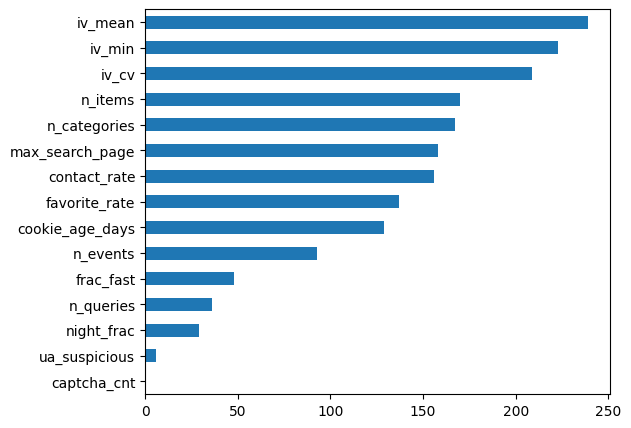

In [ ]:
m = lgb.LGBMClassifier(**params).fit(Xtr, y)
imp = pd.Series(m.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
imp.plot.barh(figsize=(6, 5)).invert_yaxis()

## 5. Финальная модель и сабмишен

Переобучаем на всём train, предсказываем test, проверяем формат.

In [ ]:
model = lgb.LGBMClassifier(**params).fit(Xtr, y)
sub = pd.DataFrame({'cookie_id': Xte.index, 'score': model.predict_proba(Xte)[:, 1]})

assert len(sub) == len(test)                 # по строке на куку
assert sub.cookie_id.is_unique               # без дубликатов
assert sub.score.between(0, 1).all()         # score в [0, 1]
assert set(sub.cookie_id) == set(test.cookie_id)

sub.to_csv('submission.csv', index=False)
sub.head()

,cookie_id,score
0,ck_315fb710a0e371e7,0.061806
1,ck_a76ee3b3e3e522fd,0.382872
2,ck_94c9a4d382689e82,0.272386
3,ck_8eaf9509ad9462a0,0.315960
4,ck_9a88a5a989cb5bc6,0.053593
